# Spooky Season Escapes; What to Expect When Flying in October

Kylie King (Georgetown University, Data Science and Analytics (DSAN))

## Traveling in October

October is considered a ‘shoulder season’ in most vacation destinations. It is situated between the summer and winter vacation seasons, perfectly in the middle of the back-to-school rush. For most families and students, October is not an ideal time to be traveling. For others, October is the perfect time to secure discounted hotels or visit popular destinations with less crowds. Whether inviting or inconvenient, what does air travel look like during this shoulder season month?

To answer this question, we looked at United States flight records from October 2024. The Department of Transportation provides Airline On-Time Performance datasets through the [TransStats portal](https://www.transtats.bts.gov/). By creating and querying a database for flights in October 2024, we are able to evaluate the busiest time of October to travel, the risks of flight cancellation, and the best airlines to take in October.

## Crows and Crowds

[InsureMyTrip analyzed TSA data](https://www.insuremytrip.com/travel-advice/travel-planning/best-worst-time-to-fly-report/) from 2023 to 2026, and found that, on average, the busiest day to fly is Sunday, and the least busy day is Tuesday. How does that yearly average compare to October?

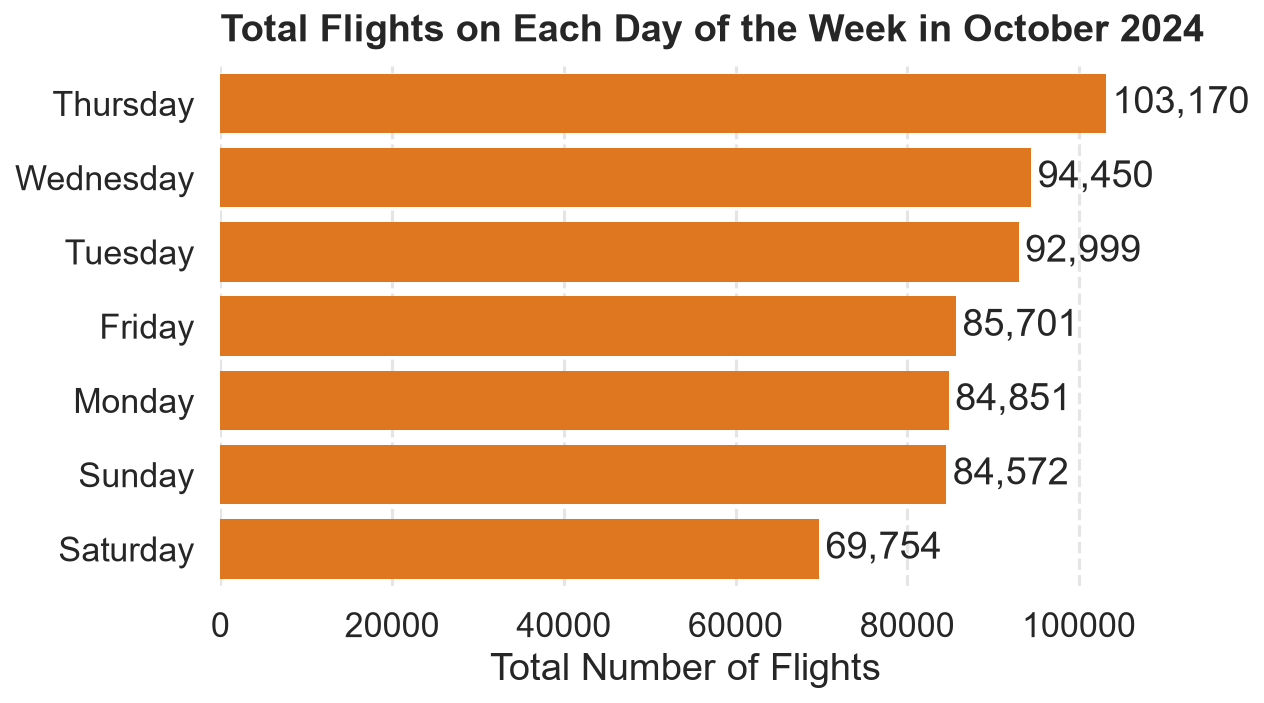

In [1]:
# busiest days
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

weekday_df = pd.read_csv("data/kylie_king_kk1543_hw4_problem_03_result.csv")
weekday_df = weekday_df.drop(weekday_df.index[-1]) #removing an 'unknown' date flight

sns.set_theme(style="whitegrid", context="talk")
fig, ax = plt.subplots(figsize=(8, 4.5), dpi=150)

sns.barplot(
    data=weekday_df,
    x="Flight_Count",
    y="Day",
    color="#ff7300",
    edgecolor="none",
    ax=ax,
)

ax.set_title("Total Flights on Each Day of the Week in October 2024", loc="left", fontweight="bold", pad=12)
ax.set_xlabel("Total Number of Flights")
ax.set_ylabel("")
ax.xaxis.grid(True, linestyle="--", alpha=0.5)
ax.yaxis.grid(False)
ax.bar_label(ax.containers[0], fmt="{:,.0f}", padding=3)
sns.despine(left=True, bottom=True)

With 103,170 flights over the course of October 2024, Thursday is actually the busiest day to fly in October! The slowest day to fly in October is Saturday, which had 69,574 flights in October 2024. Sunday, which is typically seen as the busiest day to fly, only had 84,572 flights in October 2024, making it the second slowest day of the month. Tuesday, which is typically seen as the slowest day to fly, had 92,999 flights in October 2024, making it the third busiest day of the month. This is important to keep in mind when traveling in October, as it directly contradicts the ‘common knowledge’ of flight booking.

It is important to keep in mind, however, that the time of month can also change how busy the airports are. In other months, one must consider holidays, long weekends, or other popular travel times.

Text(138.66666666666666, 0.5, '')

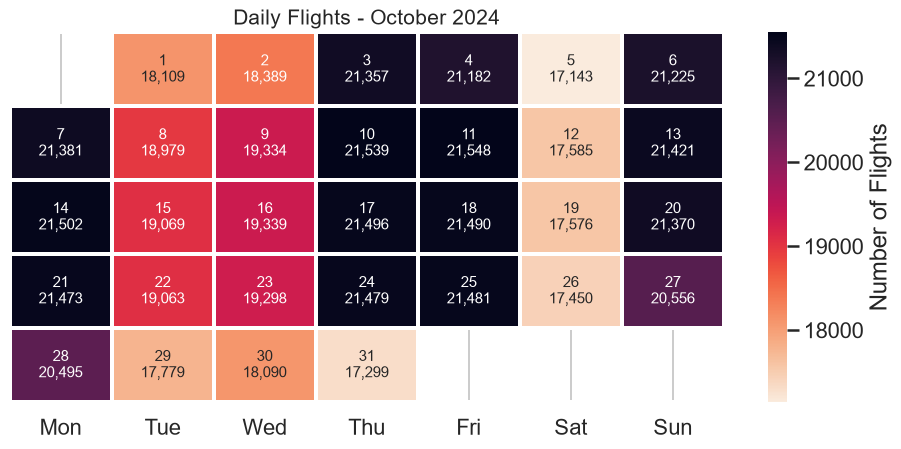

In [2]:
#making a really cool calendar visual
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import calendar

month_df = pd.read_csv("data/kylie_king_kk1543_hw4_problem_7_result.csv")

# making sure these are in datetime
month_df['FlightDate'] = pd.to_datetime(month_df['FlightDate'])

#calendar for october 2024
cal = calendar.monthcalendar(2024, 10)

calendar_data = np.full((len(cal), 7), np.nan)
annotations = np.full((len(cal), 7), '', dtype=object)

for week_idx, week in enumerate(cal):
    for day_idx, day in enumerate(week):
        if day != 0:
            flight_count = month_df.loc[
                month_df['FlightDate'].dt.day == day,
                'Flight_Count'
            ]

            count = flight_count.iloc[0] if not flight_count.empty else 0

            calendar_data[week_idx, day_idx] = count

            # date, then number of flights
            annotations[week_idx, day_idx] = f"{day}\n{count:,.0f}"
            
#remove days that are not part of the month
annotations[week_idx, day_idx] = f"{day}\n{count:,.0f}"

plt.figure(figsize=(12, 5))

sns.heatmap(
    calendar_data,
    annot=annotations,
    fmt='',
    cmap='rocket_r',
    linewidths=3,
    linecolor='white',
    cbar_kws={'label': 'Number of Flights'},
    xticklabels=['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun'],
    yticklabels=False,
    annot_kws={'fontsize': 11}
)

plt.title('Daily Flights - October 2024', fontsize=16)
plt.xlabel('')
plt.ylabel('')

In October 2024, for example, the last week of the month saw significantly fewer flights across all days. In addition, October 31st, the last day of the month, had the second fewest flights of the entire month! This decline in flights is likely because of Halloween, a fairly popular holiday.